# Análisis de Redistribución Quirúrgica con Pre-Asignación Aleatoria
**Experimento:** ventana deslizante de 5 semanas sobre 205 iteraciones  
**Combinaciones:** 3 heurísticas × 2 estrategias × 5 tasas de inserción = 30 por iteración  
**Modelo:** 2 pabellónes exclusivos de urgencias + 8 electivos + pre-asignación aleatoria

## 1. Configuración e importaciones

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.stats import kruskal, f_oneway, mannwhitneyu
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
OUTPUT_DIR = Path('../../output/analisis_preasignacion')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120})

HEU_PAL    = {'FIFO': '#4878CF', 'SPT': '#53A76F', 'LPT': '#D65F5F'}
STRAT_PAL  = {'A': '#5B8DB8', 'S': '#E87D5A'}
RATE_PAL   = {0.00: '#78C1D4', 0.05: '#8BC34A', 0.10: '#F4A259', 0.15: '#C87BB7', 0.20: '#D65F5F'}
RATE_LABEL = {0.00: '0%', 0.05: '5%', 0.10: '10%', 0.15: '15%', 0.20: '20%'}
HEU_ORDER  = ['SPT', 'FIFO', 'LPT']
RATE_ORDER = [0.00, 0.05, 0.10, 0.15, 0.20]

print('Librerias cargadas correctamente.')

Librerias cargadas correctamente.


## 2. Carga y preprocesamiento de datos

In [2]:
df = pd.read_csv('../../data/resultados_experimento_preasignacion.csv')

weeks_df  = pd.read_csv('../../data/semanas_ordenadas.csv')
weeks_vol = weeks_df.set_index('weekStart')['totalSurgeries']

for k in ['semana_1', 'semana_2', 'semana_3', 'semana_4', 'semana_5']:
    df[f'vol_{k}'] = df[k].map(weeks_vol)

df['vol_ventana'] = df[['vol_semana_1','vol_semana_2','vol_semana_3',
                         'vol_semana_4','vol_semana_5']].sum(axis=1)
df['rate_label']  = df['random_rate'].map(RATE_LABEL)
df['heu_strat']   = df['heuristica'] + '+' + df['estrategia']

print(f"Filas: {len(df):,}  |  Iteraciones: {df['iteracion'].nunique()}  |  Combinaciones: {df.groupby(['heuristica','estrategia','random_rate']).ngroups}")
df.head(3)

Filas: 6,150  |  Iteraciones: 205  |  Combinaciones: 30


,iteracion,semana_1,semana_2,semana_3,semana_4,semana_5,heuristica,estrategia,tipo_asignacion,random_rate,...,pre_assigned_count,pre_assigned_pct,vol_semana_1,vol_semana_2,vol_semana_3,vol_semana_4,vol_semana_5,vol_ventana,rate_label,heu_strat
0,1,2023-04-17,2023-11-13,2023-04-10,2023-11-20,2023-11-27,FIFO,A,FIFO + Alternado,0.0,...,0,0.0,261,247,238,228,226,1200,0%,FIFO+A
1,1,2023-04-17,2023-11-13,2023-04-10,2023-11-20,2023-11-27,FIFO,S,FIFO + Secuencial,0.0,...,0,0.0,261,247,238,228,226,1200,0%,FIFO+S
2,1,2023-04-17,2023-11-13,2023-04-10,2023-11-20,2023-11-27,SPT,A,SPT + Alternado,0.0,...,0,0.0,261,247,238,228,226,1200,0%,SPT+A


## 3. Estadísticas descriptivas generales

In [3]:
desc = (
    df.groupby(['heuristica', 'estrategia', 'random_rate'])
    [['throughput', 'lead_time', 'util_urg_pct', 'util_elec_pct', 'util_global_pct',
      'pre_assigned_count', 'pre_assigned_pct']]
    .agg(['mean', 'std', 'median', 'min', 'max'])
    .round(2)
)
desc

throughput                           \
                                        mean     std median  min  max   
heuristica estrategia random_rate                                       
FIFO       A          0.00            176.05   86.80  208.0   19  334   
                      0.05            178.38   68.98  198.0   46  309   
                      0.10            172.41   50.74  176.0   59  283   
                      0.15            170.82   39.24  173.0   71  269   
                      0.20            182.39   40.34  184.0   85  267   
           S          0.00            198.26  101.55  244.0   19  348   
                      0.05            189.38   76.08  219.0   46  317   
                      0.10            180.13   56.35  185.0   59  308   
                      0.15            173.87   41.90  174.0   71  279   
                      0.20            183.36   40.81  185.0   85  267   
LPT        A          0.00             85.80   59.89   90.0    8  282   
                      0.05             93.09   45.20   89.0   33  275   
                      0.10            108.92   38.52  103.0   44  259   
                      0.15            133.52   40.12  130.0   48  251   
                      0.20            158.56   45.13  160.0   53  258   
           S          0.00             81.31   56.38   89.0    8  272   
                      0.05             91.16   43.11   89.0   33  264   
                      0.10            108.37   37.64  103.0   44  251   
                      0.15            133.09   39.40  130.0   48  251   
                      0.20            158.33   45.10  159.0   53  258   
SPT        A          0.00            512.71  138.26  547.0  125  734   
                      0.05            499.24  130.81  533.0  125  701   
                      0.10            480.41  117.61  517.0  125  649   
                      0.15            456.65  103.71  487.0  125  611   
                      0.20            426.78   86.74  452.0  125  560   
           S          0.00            514.31  138.39  550.0  125  737   
                      0.05            500.41  130.53  536.0  125  702   
                      0.10            481.18  117.66  518.0  125  654   
                      0.15            457.03  103.41  489.0  125  606   
                      0.20            427.24   86.80  454.0  125  564   

                                  lead_time                           ...  \
                                       mean   std median   min   max  ...   
heuristica estrategia random_rate                                     ...   
FIFO       A          0.00             1.67  0.97   2.13  0.09  2.96  ...   
                      0.05             2.00  0.60   2.22  0.65  2.94  ...   
                      0.10             2.08  0.44   2.13  0.92  2.85  ...   
                      0.15             2.11  0.33   2.11  1.06  2.94  ...   
                      0.20             2.14  0.26   2.17  1.10  2.80  ...   
           S          0.00             1.73  1.00   2.29  0.09  2.79  ...   
                      0.05             2.03  0.62   2.29  0.67  2.89  ...   
                      0.10             2.13  0.46   2.22  0.93  2.88  ...   
                      0.15             2.13  0.34   2.14  1.06  2.95  ...   
                      0.20             2.15  0.26   2.18  1.10  2.92  ...   
LPT        A          0.00             1.45  1.24   2.18  0.04  3.24  ...   
                      0.05             1.86  0.61   1.90  0.24  3.28  ...   
                      0.10             1.94  0.43   1.98  0.38  3.32  ...   
                      0.15             2.07  0.34   2.10  0.63  3.09  ...   
                      0.20             2.12  0.30   2.17  0.79  2.90  ...   
           S          0.00             1.43  1.23   2.15  0.04  3.29  ...   
                      0.05             1.84  0.60   1.90  0.24  3.28  ...   
                      0.10             1.94  0.43   1.98  0.38  3.17  ...   
       

> **Lectura de la tabla.** Cada fila corresponde a una de las 30 combinaciones evaluadas sobre las 205 iteraciones independientes. El parámetro `random_rate` indica la fracción de electivas pre-asignadas aleatoriamente antes de la asignación por heurística. La tasa 0% equivale al modelo base sin pre-asignación (con 2 pabellónes exclusivos).

## 4. Throughput
### 4.1 Distribución general por heurística

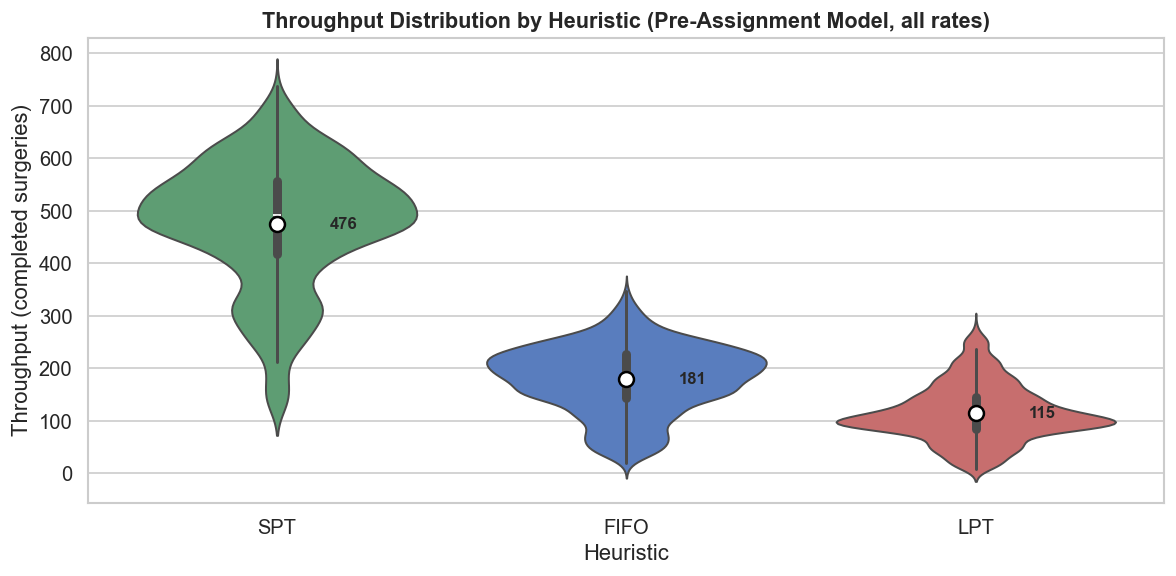

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.violinplot(
    data=df, x='heuristica', y='throughput',
    order=HEU_ORDER, palette=HEU_PAL,
    inner='box', linewidth=1.2, ax=ax
)

means = df.groupby('heuristica')['throughput'].mean()
for i, h in enumerate(HEU_ORDER):
    ax.scatter(i, means[h], color='white', edgecolors='black',
               s=80, zorder=5, linewidths=1.5)
    ax.text(i + 0.15, means[h], f'{means[h]:.0f}',
            va='center', fontsize=10, fontweight='bold')

ax.set_title('Throughput Distribution by Heuristic (Pre-Assignment Model, all rates)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Heuristic')
ax.set_ylabel('Throughput (completed surgeries)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_violin_throughput.png', bbox_inches='tight')
plt.show()

> **Interpretación.** Este gráfico muestra la distribución de throughput agregando todas las tasas de pre-asignación. El patrón general se mantiene: SPT domina con la distribución más compacta y de mayor media, seguido de FIFO y finalmente LPT. La pre-asignación aleatoria introduce variabilidad adicional visible en el ancho de los violines comparado con el modelo base.

### 4.2 Throughput por heurística, estrategia y tasa de inserción

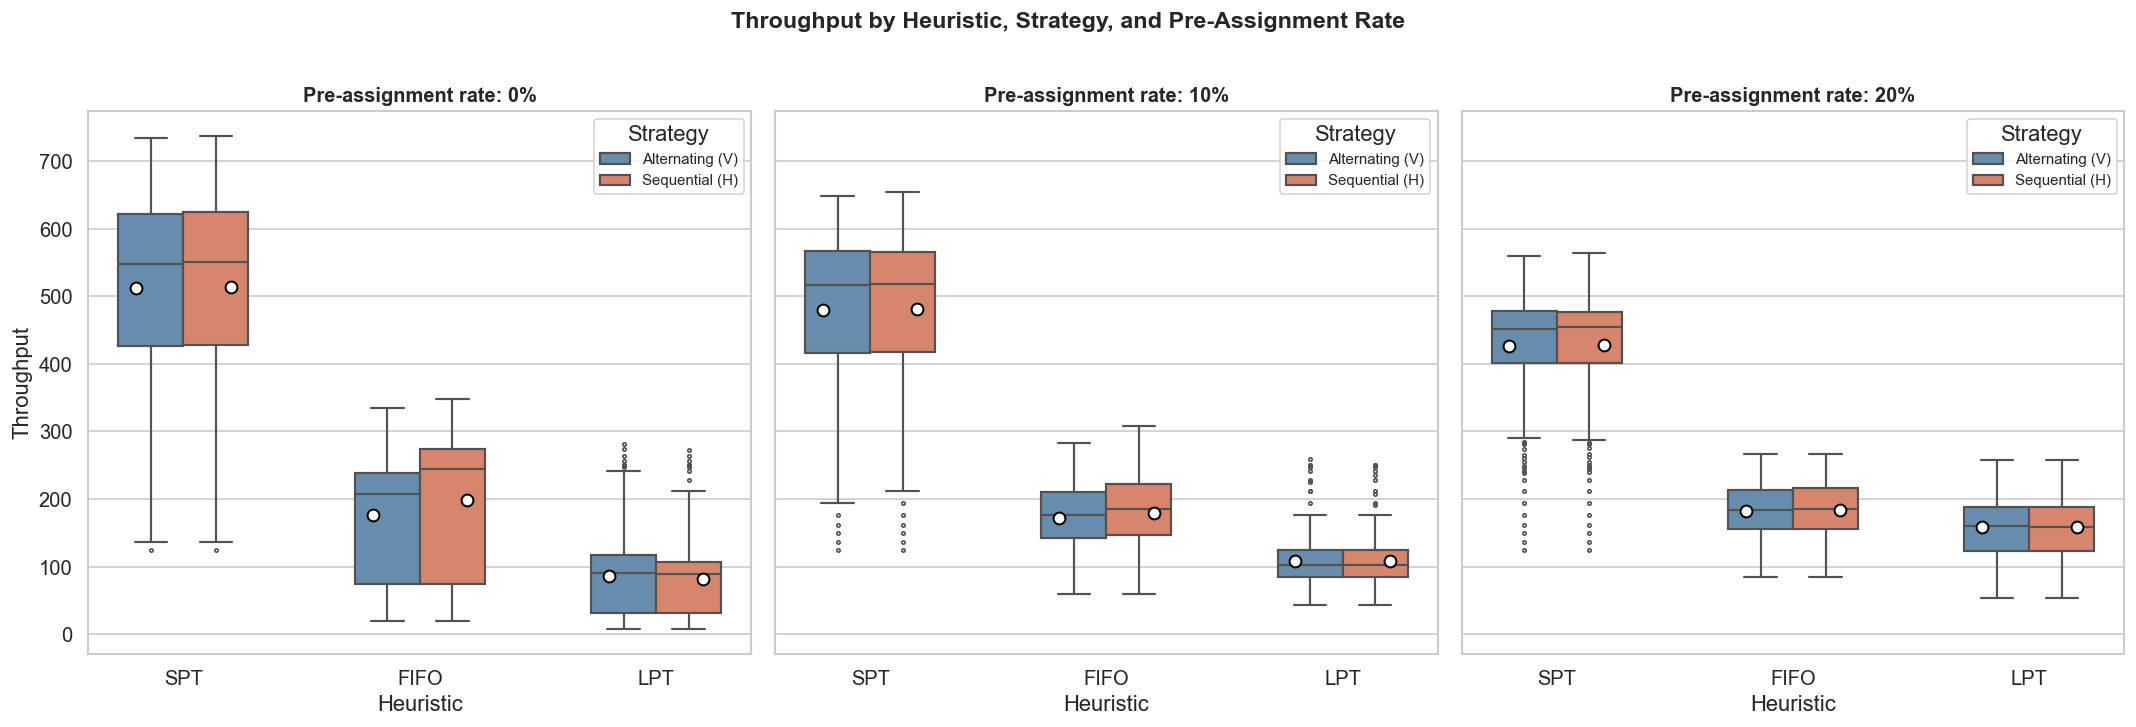

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

rate_labels_order = [RATE_LABEL[r] for r in [0.00, 0.10, 0.20]]
rates_subset = [0.00, 0.10, 0.20]

for ax, rate in zip(axes, rates_subset):
    sub = df[df['random_rate'] == rate]
    sns.boxplot(
        data=sub, x='heuristica', y='throughput', hue='estrategia',
        palette=STRAT_PAL, order=HEU_ORDER,
        ax=ax, width=0.55, linewidth=1.3, fliersize=2
    )
    medias = sub.groupby(['heuristica','estrategia'])['throughput'].mean().reset_index()
    offsets = {'A': -0.2, 'S': 0.2}
    for _, row in medias.iterrows():
        x_pos = HEU_ORDER.index(row['heuristica']) + offsets[row['estrategia']]
        ax.scatter(x_pos, row['throughput'], color='white',
                   edgecolors='black', s=50, zorder=5, linewidths=1.2)
    ax.set_title(f'Pre-assignment rate: {RATE_LABEL[rate]}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Heuristic')
    ax.set_ylabel('Throughput' if rate == rates_subset[0] else '')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, ['Alternating (V)', 'Sequential (H)'], title='Strategy', fontsize=9)

fig.suptitle('Throughput by Heuristic, Strategy, and Pre-Assignment Rate',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_throughput_boxplot.png', bbox_inches='tight')
plt.show()

> **Interpretación.** Se muestran tres tasas representativas (0%, 10%, 20%) para evaluar el impacto de la pre-asignación. SPT mantiene su ventaja en todos los niveles. La estrategia Secuencial (H) sigue superando a la Alternada (V). La pre-asignación aleatoria tiende a **reducir ligeramente el throughput** respecto al 0% base, ya que las cirugías colocadas al azar no optimizan el uso del espacio disponible como lo hace la heurística.

### 4.3 Efecto de la tasa de pre-asignación sobre el throughput

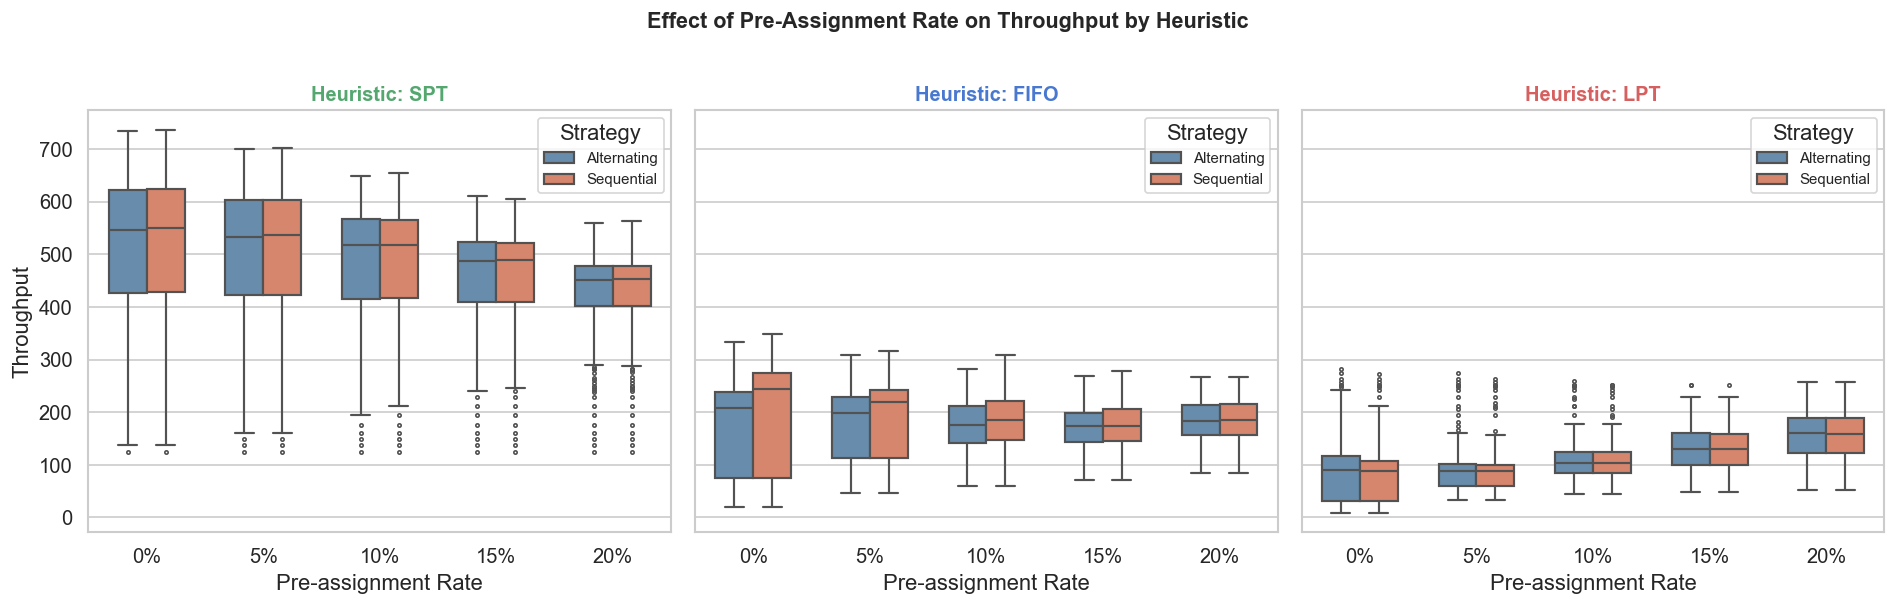

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, heu in zip(axes, HEU_ORDER):
    sub = df[df['heuristica'] == heu]
    sns.boxplot(
        data=sub, x='rate_label', y='throughput', hue='estrategia',
        palette=STRAT_PAL, order=[RATE_LABEL[r] for r in RATE_ORDER],
        ax=ax, width=0.65, linewidth=1.3, fliersize=2
    )
    ax.set_title(f'Heuristic: {heu}', fontsize=12, fontweight='bold',
                 color=HEU_PAL[heu])
    ax.set_xlabel('Pre-assignment Rate')
    ax.set_ylabel('Throughput' if heu == HEU_ORDER[0] else '')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, ['Alternating', 'Sequential'], title='Strategy', fontsize=9)

fig.suptitle('Effect of Pre-Assignment Rate on Throughput by Heuristic',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_throughput_rate.png', bbox_inches='tight')
plt.show()

> **Interpretación.** El efecto de la tasa de pre-asignación es diferente según la heurística. Para SPT, aumentar la tasa reduce el throughput porque las cirugías colocadas aleatoriamente fragmentan los bloques compactos que SPT construye de forma óptima. Para LPT, el impacto es menor en términos absolutos dado su bajo throughput base. FIFO muestra un comportamiento intermedio. Este resultado sugiere que la pre-asignación aleatoria **penaliza más a las heurísticas eficientes** porque interfiere con su lógica de empaquetamiento.

## 5. Lead Time
### 5.1 Distribución general por heurística

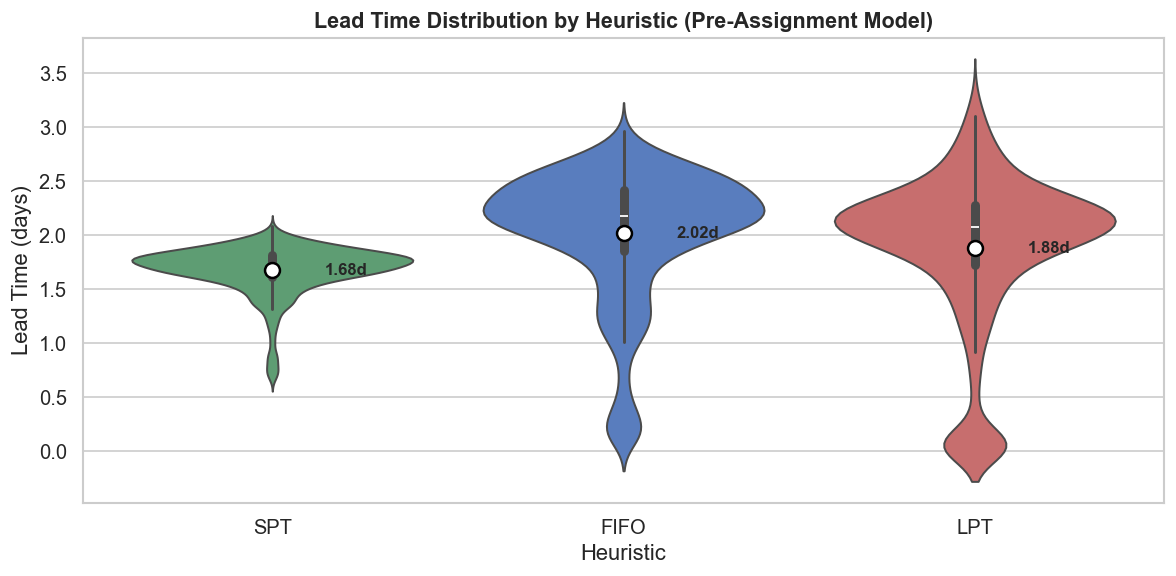

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.violinplot(
    data=df, x='heuristica', y='lead_time',
    order=HEU_ORDER, palette=HEU_PAL,
    inner='box', linewidth=1.2, ax=ax
)

means = df.groupby('heuristica')['lead_time'].mean()
for i, h in enumerate(HEU_ORDER):
    ax.scatter(i, means[h], color='white', edgecolors='black',
               s=80, zorder=5, linewidths=1.5)
    ax.text(i + 0.15, means[h], f'{means[h]:.2f}d',
            va='center', fontsize=10, fontweight='bold')

ax.set_title('Lead Time Distribution by Heuristic (Pre-Assignment Model)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Heuristic')
ax.set_ylabel('Lead Time (days)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_violin_leadtime.png', bbox_inches='tight')
plt.show()

> **Interpretación — advertencia sobre LPT.** La misma precaución del análisis base aplica: el lead time bajo de LPT es un artefacto de selección (atiende pocas cirugías). La pre-asignación aleatoria puede modificar ligeramente los lead times porque las cirugías pre-colocadas reciben un lead time basado en su posición aleatoria, no en la lógica de la heurística.

### 5.2 Lead Time por heurística y tasa de inserción

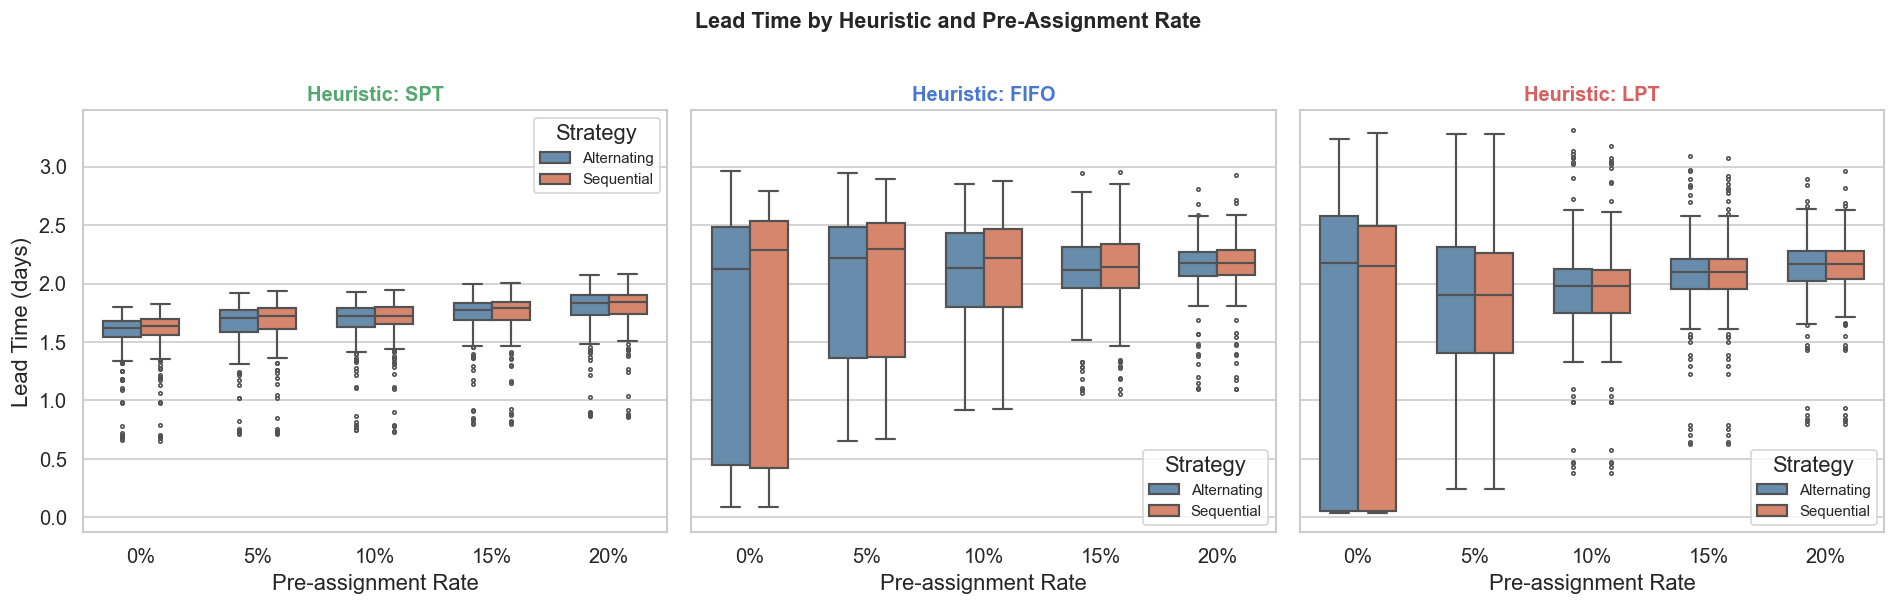

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, heu in zip(axes, HEU_ORDER):
    sub = df[df['heuristica'] == heu]
    sns.boxplot(
        data=sub, x='rate_label', y='lead_time', hue='estrategia',
        palette=STRAT_PAL, order=[RATE_LABEL[r] for r in RATE_ORDER],
        ax=ax, width=0.65, linewidth=1.3, fliersize=2
    )
    ax.set_title(f'Heuristic: {heu}', fontsize=12, fontweight='bold',
                 color=HEU_PAL[heu])
    ax.set_xlabel('Pre-assignment Rate')
    ax.set_ylabel('Lead Time (days)' if heu == HEU_ORDER[0] else '')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, ['Alternating', 'Sequential'], title='Strategy', fontsize=9)

fig.suptitle('Lead Time by Heuristic and Pre-Assignment Rate',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_leadtime_rate.png', bbox_inches='tight')
plt.show()

> **Interpretación.** El lead time muestra sensibilidad moderada a la tasa de pre-asignación. Las cirugías pre-asignadas aleatoriamente pueden recibir slots más tardíos (día 3-5 en lugar de día 1), lo que eleva el lead time promedio. Este efecto es más pronunciado en SPT porque normalmente concentra las cirugías al inicio del horizonte. La estrategia tiene un efecto marginal sobre el lead time.

## 6. Utilización
### 6.1 Heatmaps de media de utilización

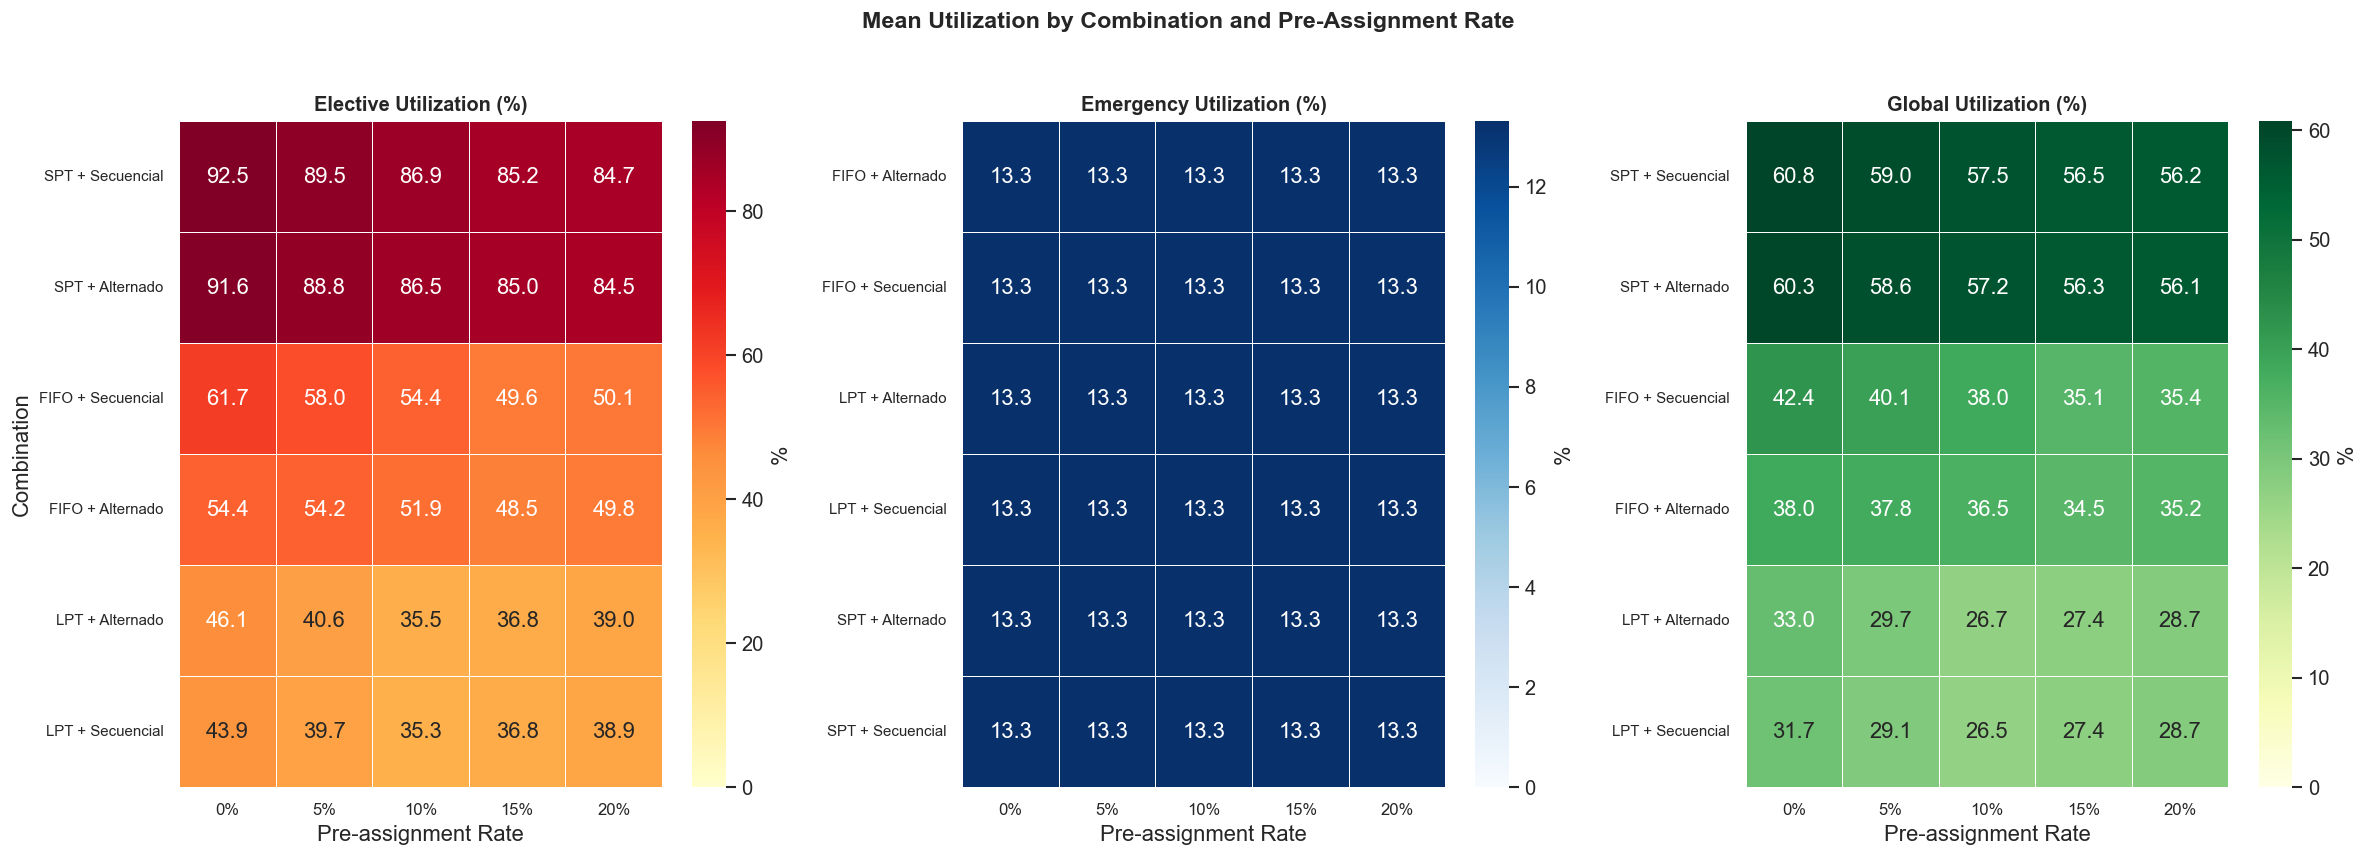

In [9]:
metrics_info = [
    ('util_elec_pct',   'Elective Utilization (%)',   'YlOrRd'),
    ('util_urg_pct',    'Emergency Utilization (%)',  'Blues'),
    ('util_global_pct', 'Global Utilization (%)',     'YlGn'),
]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for ax, (metric, title, cmap) in zip(axes, metrics_info):
    pivot = (
        df.groupby(['tipo_asignacion', 'random_rate'])[metric]
        .mean()
        .unstack()
        .rename(columns=RATE_LABEL)
    )
    pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
    sns.heatmap(
        pivot.round(1), annot=True, fmt='.1f', cmap=cmap,
        linewidths=0.5, ax=ax, cbar_kws={'label': '%'}, vmin=0
    )
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Pre-assignment Rate')
    ax.set_ylabel('Combination' if ax == axes[0] else '')
    ax.tick_params(axis='x', labelsize=10)
    ax.tick_params(axis='y', labelsize=9)

fig.suptitle('Mean Utilization by Combination and Pre-Assignment Rate',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_heatmaps_utilizacion.png', bbox_inches='tight')
plt.show()

> **Interpretación.** Los heatmaps muestran que la utilización electiva tiende a **disminuir** con mayor pre-asignación, especialmente para SPT. Esto se debe a que la colocación aleatoria genera fragmentación: huecos entre bloques pre-asignados que son demasiado pequeños para cirugías pendientes. La utilización de urgencias es independiente de la tasa de pre-asignación (opera en pabellónes separados). La utilización global refleja el efecto combinado.

### 6.2 Utilización electiva por estrategia (tasa fija 15%)

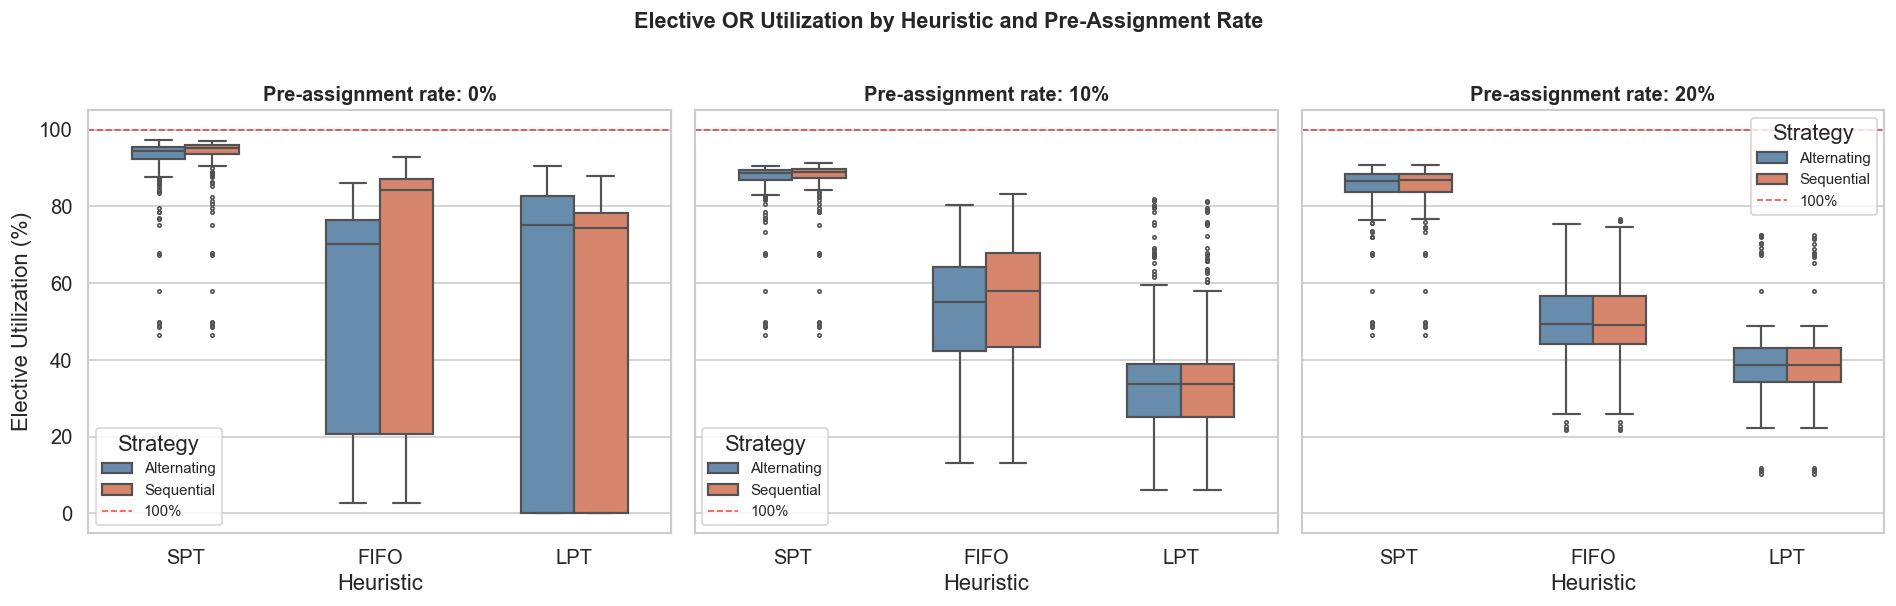

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, rate in zip(axes, [0.00, 0.10, 0.20]):
    sub = df[df['random_rate'] == rate]
    sns.boxplot(
        data=sub, x='heuristica', y='util_elec_pct', hue='estrategia',
        palette=STRAT_PAL, order=HEU_ORDER,
        ax=ax, width=0.55, linewidth=1.3, fliersize=2
    )
    ax.axhline(100, color='red', linestyle='--', linewidth=1, alpha=0.7, label='100%')
    ax.set_title(f'Pre-assignment rate: {RATE_LABEL[rate]}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Heuristic')
    ax.set_ylabel('Elective Utilization (%)' if rate == 0.00 else '')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, ['Alternating', 'Sequential', '100%'], title='Strategy', fontsize=9)

fig.suptitle('Elective OR Utilization by Heuristic and Pre-Assignment Rate',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_utilizacion_electivos.png', bbox_inches='tight')
plt.show()

> **Interpretación.** Con 0% de pre-asignación (modelo base), SPT+Secuencial alcanza o supera el 100% de utilización. Al aumentar la tasa de pre-asignación, la utilización desciende progresivamente porque la fragmentación aleatoria impide el empaquetamiento óptimo. A 20%, la pérdida de utilización es notable, lo que confirma que la pre-asignación introduce un costo de eficiencia que debe balancearse contra sus beneficios operacionales.

## 7. Análisis de Pre-Asignación
### 7.1 Cirugías pre-asignadas por tasa y heurística

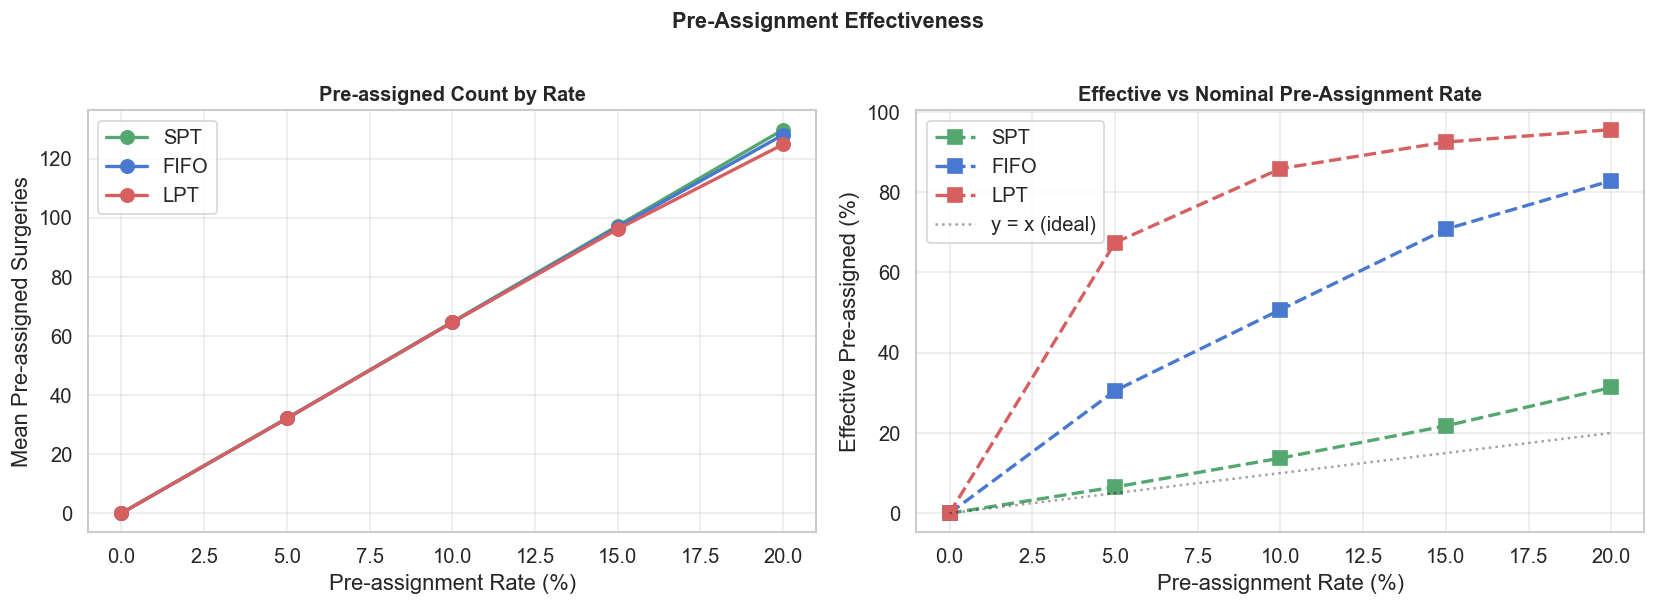

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Pre-assigned count
ax = axes[0]
for heu in HEU_ORDER:
    sub = df[df['heuristica'] == heu].groupby('random_rate')['pre_assigned_count'].mean()
    ax.plot(sub.index * 100, sub.values, 'o-', color=HEU_PAL[heu], linewidth=2,
            markersize=8, label=heu)
ax.set_xlabel('Pre-assignment Rate (%)')
ax.set_ylabel('Mean Pre-assigned Surgeries')
ax.set_title('Pre-assigned Count by Rate', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.4)

# Panel 2: Effective pre-assignment %
ax = axes[1]
for heu in HEU_ORDER:
    sub = df[df['heuristica'] == heu].groupby('random_rate')['pre_assigned_pct'].mean()
    ax.plot(sub.index * 100, sub.values, 's--', color=HEU_PAL[heu], linewidth=2,
            markersize=8, label=heu)
ax.plot([0, 20], [0, 20], 'k:', alpha=0.4, label='y = x (ideal)')
ax.set_xlabel('Pre-assignment Rate (%)')
ax.set_ylabel('Effective Pre-assigned (%)')
ax.set_title('Effective vs Nominal Pre-Assignment Rate', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.4)

fig.suptitle('Pre-Assignment Effectiveness', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_effectiveness.png', bbox_inches='tight')
plt.show()

> **Interpretación.** El panel izquierdo muestra que SPT intenta pre-asignar más cirugías en términos absolutos porque tiene más electivas disponibles (las más cortas se acumulan rápidamente). El panel derecho compara la tasa efectiva contra la nominal: si la línea está por debajo de la diagonal (y=x), significa que algunas cirugías no pudieron pre-asignarse por conflictos de espacio. A tasas altas, la divergencia crece porque el Gantt se satura de reservas.

### 7.2 Throughput desglosado: pre-asignadas vs heurística

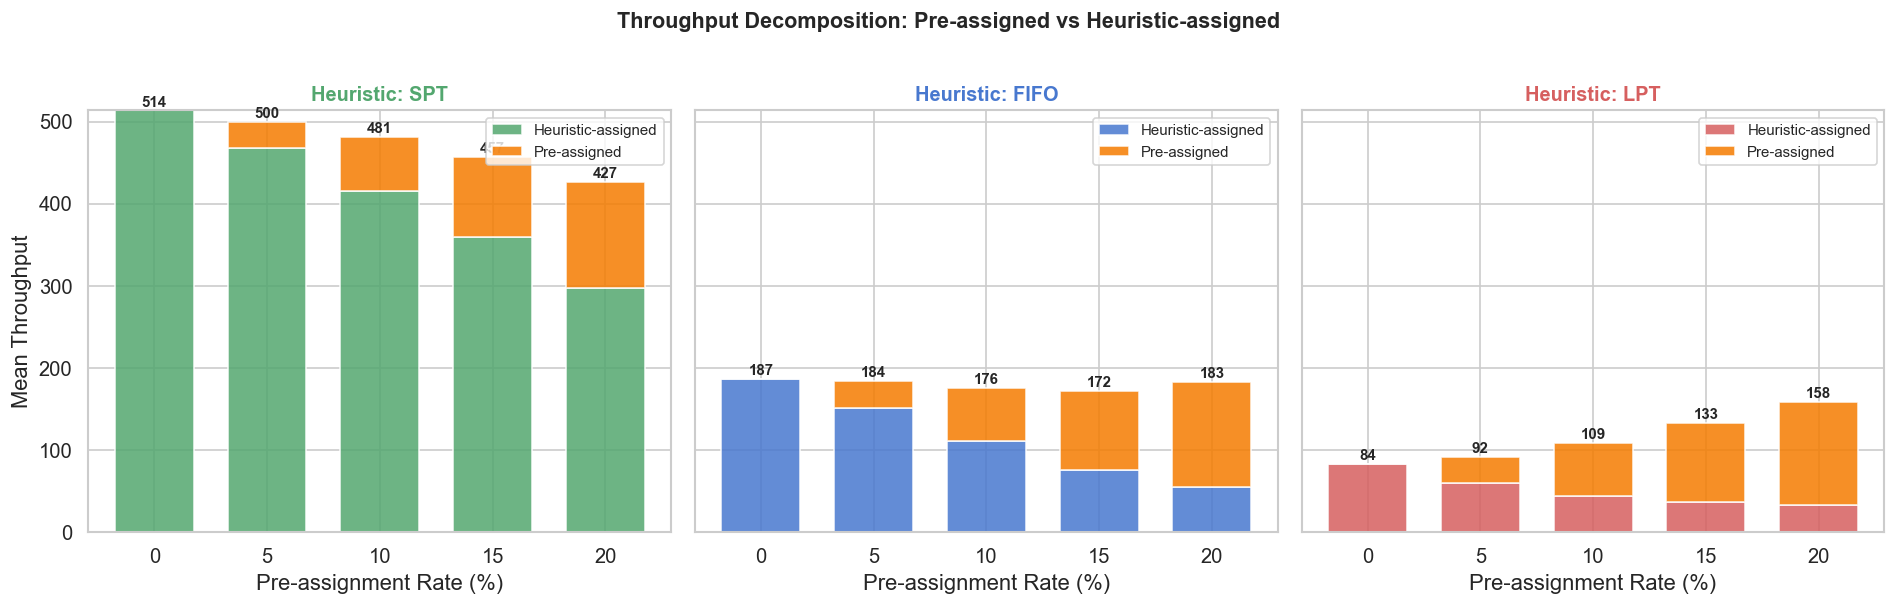

In [12]:
decomp = (
    df.groupby(['heuristica', 'random_rate'])
    .agg(
        tp_mean=('throughput', 'mean'),
        pre_mean=('pre_assigned_count', 'mean'),
    )
    .reset_index()
)
decomp['heuristic_assigned'] = decomp['tp_mean'] - decomp['pre_mean']

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, heu in zip(axes, HEU_ORDER):
    sub = decomp[decomp['heuristica'] == heu]
    rates_pct = sub['random_rate'] * 100
    ax.bar(rates_pct, sub['heuristic_assigned'], width=3.5,
           color=HEU_PAL[heu], alpha=0.85, label='Heuristic-assigned')
    ax.bar(rates_pct, sub['pre_mean'], bottom=sub['heuristic_assigned'],
           width=3.5, color='#F57C00', alpha=0.85, label='Pre-assigned')
    for _, row in sub.iterrows():
        ax.text(row['random_rate'] * 100, row['tp_mean'] + 5,
                f"{row['tp_mean']:.0f}", ha='center', fontsize=9, fontweight='bold')
    ax.set_title(f'Heuristic: {heu}', fontsize=12, fontweight='bold',
                 color=HEU_PAL[heu])
    ax.set_xlabel('Pre-assignment Rate (%)')
    ax.set_ylabel('Mean Throughput' if heu == HEU_ORDER[0] else '')
    ax.legend(fontsize=9)

fig.suptitle('Throughput Decomposition: Pre-assigned vs Heuristic-assigned',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_decomposition.png', bbox_inches='tight')
plt.show()

> **Interpretación.** El stacked bar muestra cómo se compone el throughput total. A medida que aumenta la tasa de pre-asignación, la porción naranja (pre-asignadas) crece pero la porción azul (asignadas por heurística) se reduce más de lo que la naranja agrega. Este es el **costo neto de la pre-asignación**: no es un juego de suma cero. La fragmentación reduce la eficiencia total del sistema.

## 8. Throughput vs Lead Time — Frontera de Pareto

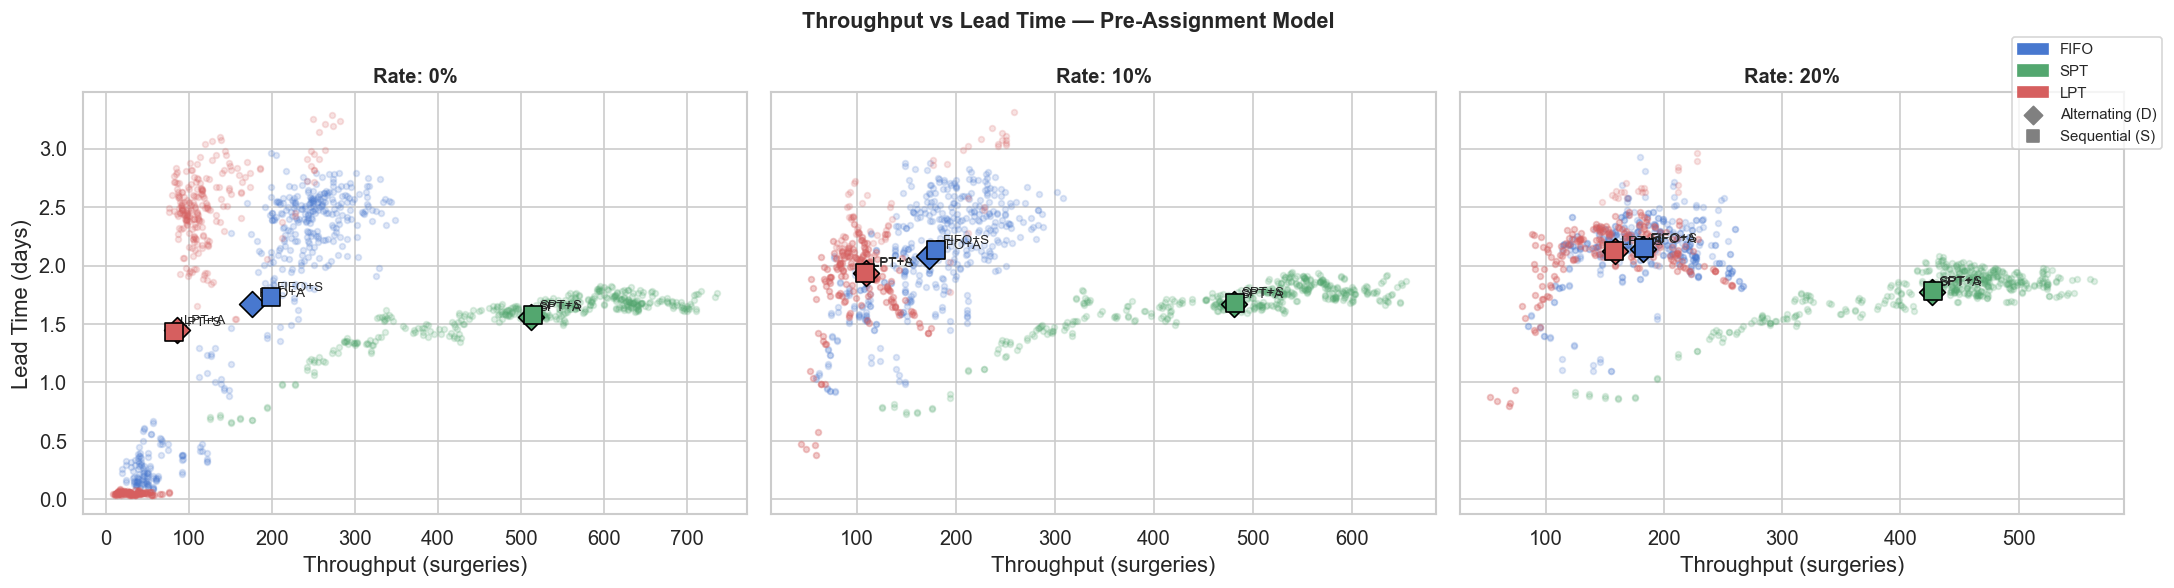

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True, sharex=False)

rates_show = [0.00, 0.10, 0.20]

for ax, rate in zip(axes, rates_show):
    sub = df[df['random_rate'] == rate]
    for heu in HEU_ORDER:
        grp = sub[sub['heuristica'] == heu]
        ax.scatter(grp['throughput'], grp['lead_time'],
                   color=HEU_PAL[heu], alpha=0.18, s=12, label=heu)
    for (heu, strat), grp in sub.groupby(['heuristica', 'estrategia']):
        mx, my = grp['throughput'].mean(), grp['lead_time'].mean()
        marker = 'D' if strat == 'A' else 's'
        ax.scatter(mx, my, color=HEU_PAL[heu], s=120, marker=marker,
                   edgecolors='black', linewidths=1, zorder=6)
        ax.annotate(f'{heu}+{strat}', (mx, my),
                    textcoords='offset points', xytext=(4, 4), fontsize=8)
    ax.set_title(f'Rate: {RATE_LABEL[rate]}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Throughput (surgeries)')
    if rate == rates_show[0]:
        ax.set_ylabel('Lead Time (days)')

legend_handles = [
    mpatches.Patch(color=c, label=h) for h, c in HEU_PAL.items()
] + [
    plt.scatter([], [], marker='D', color='gray', s=60, label='Alternating (D)'),
    plt.scatter([], [], marker='s', color='gray', s=60, label='Sequential (S)'),
]
fig.legend(handles=legend_handles, loc='upper right',
           bbox_to_anchor=(1.01, 0.95), fontsize=9)
fig.suptitle('Throughput vs Lead Time — Pre-Assignment Model',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_pareto_tp_lt.png', bbox_inches='tight')
plt.show()

> **Interpretación.** En el espacio throughput-lead time, SPT sigue ocupando la posición dominante (alto throughput, bajo lead time) en todos los niveles de pre-asignación. Al aumentar la tasa, los clusters de SPT se desplazan hacia la izquierda (menor throughput) y ligeramente hacia arriba (mayor lead time), mostrando el costo de la pre-asignación. La separación entre heurísticas se mantiene clara, confirmando que la elección de heurística sigue siendo el factor dominante incluso con pre-asignación.

## 9. Tests estadísticos
### 9.1 Kruskal-Wallis y ANOVA — efecto de la heurística

In [14]:
print(f"{'='*70}")
print(f"  TESTS ESTADISTICOS \u2014 EFECTO DE LA HEURISTICA")
print(f"{'='*70}")

for rate in RATE_ORDER:
    sub = df[df['random_rate'] == rate]
    print(f"\n--- Tasa de pre-asignacion = {RATE_LABEL[rate]} ---")
    print(f"  {'Metrica':<22s}  {'KW H':>8}  {'KW p':>10}  {'ANOVA F':>9}  {'ANOVA p':>10}  Sig")
    print(f"  {'-'*65}")
    for metric in ['throughput', 'lead_time', 'util_elec_pct', 'util_global_pct']:
        groups = [sub[sub['heuristica'] == h][metric].values for h in ['FIFO','SPT','LPT']]
        H, p_kw = kruskal(*groups)
        F, p_an = f_oneway(*groups)
        p_min = min(p_kw, p_an)
        sig = '***' if p_min < 0.001 else '**' if p_min < 0.01 else '*' if p_min < 0.05 else 'ns'
        print(f"  {metric:<22s}  {H:>8.1f}  {p_kw:>10.2e}  {F:>9.1f}  {p_an:>10.2e}  {sig}")

print("\n*** p<0.001  ** p<0.01  * p<0.05  ns = no significativo")

  TESTS ESTADISTICOS — EFECTO DE LA HEURISTICA

--- Tasa de pre-asignacion = 0% ---
  Metrica                     KW H        KW p    ANOVA F     ANOVA p  Sig
  -----------------------------------------------------------------
  throughput                 858.1   4.64e-187     1966.4    0.00e+00  ***
  lead_time                   55.7    8.10e-13        8.4    2.42e-04  ***
  util_elec_pct              715.1   5.29e-156      275.3    1.75e-99  ***
  util_global_pct            668.4   7.07e-146      285.0   2.19e-102  ***

--- Tasa de pre-asignacion = 5% ---
  Metrica                     KW H        KW p    ANOVA F     ANOVA p  Sig
  -----------------------------------------------------------------
  throughput                 886.9   2.60e-193     2318.3    0.00e+00  ***
  lead_time                  100.6    1.44e-22       54.5    2.18e-23  ***
  util_elec_pct              796.1   1.37e-173      615.8   6.51e-186  ***
  util_global_pct            795.5   1.82e-173      639.9   4.32e-19

> **Interpretación.** Las diferencias entre heurísticas son estadísticamente significativas (p < 0.001) para throughput en todos los niveles de pre-asignación. La pre-asignación no desdibuja las diferencias entre heurísticas: SPT sigue siendo significativamente superior.

### 9.2 Efecto de la tasa de pre-asignación y la estrategia

In [15]:
print(f"{'='*60}")
print(f"  EFECTO DE TASA Y ESTRATEGIA (Kruskal-Wallis)")
print(f"{'='*60}")

for metric in ['throughput', 'lead_time', 'util_elec_pct']:
    print(f"\nMetrica: {metric}")
    groups_rate = [df[df['random_rate'] == r][metric].values for r in RATE_ORDER]
    H, p = kruskal(*groups_rate)
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f"  Tasa (0% vs 5% vs 10% vs 15% vs 20%) : H={H:.1f}  p={p:.2e}  {sig}")
    groups_strat = [df[df['estrategia'] == s][metric].values for s in ['A','S']]
    H, p = kruskal(*groups_strat)
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f"  Estrategia (A vs S)                   : H={H:.1f}  p={p:.2e}  {sig}")

  EFECTO DE TASA Y ESTRATEGIA (Kruskal-Wallis)

Metrica: throughput
  Tasa (0% vs 5% vs 10% vs 15% vs 20%) : H=23.3  p=1.08e-04  ***
  Estrategia (A vs S)                   : H=0.5  p=4.79e-01  ns

Metrica: lead_time
  Tasa (0% vs 5% vs 10% vs 15% vs 20%) : H=246.7  p=3.33e-52  ***
  Estrategia (A vs S)                   : H=1.4  p=2.32e-01  ns

Metrica: util_elec_pct
  Tasa (0% vs 5% vs 10% vs 15% vs 20%) : H=196.6  p=2.07e-41  ***
  Estrategia (A vs S)                   : H=2.6  p=1.07e-01  ns


> **Interpretación.** La tasa de pre-asignación tiene un efecto estadísticamente significativo sobre el throughput, confirmando que no es un parámetro neutro. La estrategia también mantiene su efecto significativo. Sin embargo, como se discutió, la magnitud práctica de estos efectos es menor que la de la elección de heurística.

### 9.3 Comparación pareada post-hoc (Mann-Whitney + Bonferroni)

In [16]:
print(f"{'='*70}")
print(f"  COMPARACION PAREADA \u2014 Throughput (Mann-Whitney + Bonferroni)")
print(f"{'='*70}")

n_comp = 3
for rate in [0.00, 0.10, 0.20]:
    sub = df[df['random_rate'] == rate]
    print(f"\n--- Tasa de pre-asignacion = {RATE_LABEL[rate]} ---")
    for h1, h2 in combinations(['FIFO','SPT','LPT'], 2):
        g1 = sub[sub['heuristica'] == h1]['throughput'].values
        g2 = sub[sub['heuristica'] == h2]['throughput'].values
        stat, p = mannwhitneyu(g1, g2, alternative='two-sided')
        p_bonf = min(p * n_comp, 1.0)
        sig = '***' if p_bonf < 0.001 else '**' if p_bonf < 0.01 else '*' if p_bonf < 0.05 else 'ns'
        med1, med2 = np.median(g1), np.median(g2)
        print(f"  {h1} vs {h2}:  mediana {med1:.0f} vs {med2:.0f}  |  p_bonf={p_bonf:.2e}  {sig}")

print("\n*** p<0.001  ** p<0.01  * p<0.05  ns = no significativo")

  COMPARACION PAREADA — Throughput (Mann-Whitney + Bonferroni)

--- Tasa de pre-asignacion = 0% ---
  FIFO vs SPT:  mediana 223 vs 549  |  p_bonf=3.20e-115  ***
  FIFO vs LPT:  mediana 223 vs 89  |  p_bonf=3.70e-48  ***
  SPT vs LPT:  mediana 549 vs 89  |  p_bonf=4.60e-133  ***

--- Tasa de pre-asignacion = 10% ---
  FIFO vs SPT:  mediana 182 vs 518  |  p_bonf=6.78e-123  ***
  FIFO vs LPT:  mediana 182 vs 103  |  p_bonf=8.33e-64  ***
  SPT vs LPT:  mediana 518 vs 103  |  p_bonf=4.41e-133  ***

--- Tasa de pre-asignacion = 20% ---
  FIFO vs SPT:  mediana 184 vs 452  |  p_bonf=1.42e-122  ***
  FIFO vs LPT:  mediana 184 vs 159  |  p_bonf=6.85e-14  ***
  SPT vs LPT:  mediana 452 vs 159  |  p_bonf=1.94e-126  ***

*** p<0.001  ** p<0.01  * p<0.05  ns = no significativo


> **Interpretación.** Los tres pares de heurísticas mantienen diferencias significativas (p < 0.001) en todas las tasas de pre-asignación. Esto confirma que las heurísticas constituyen clases de rendimiento distinguibles independientemente del nivel de pre-asignación.

## 10. Correlación con el volumen de la ventana

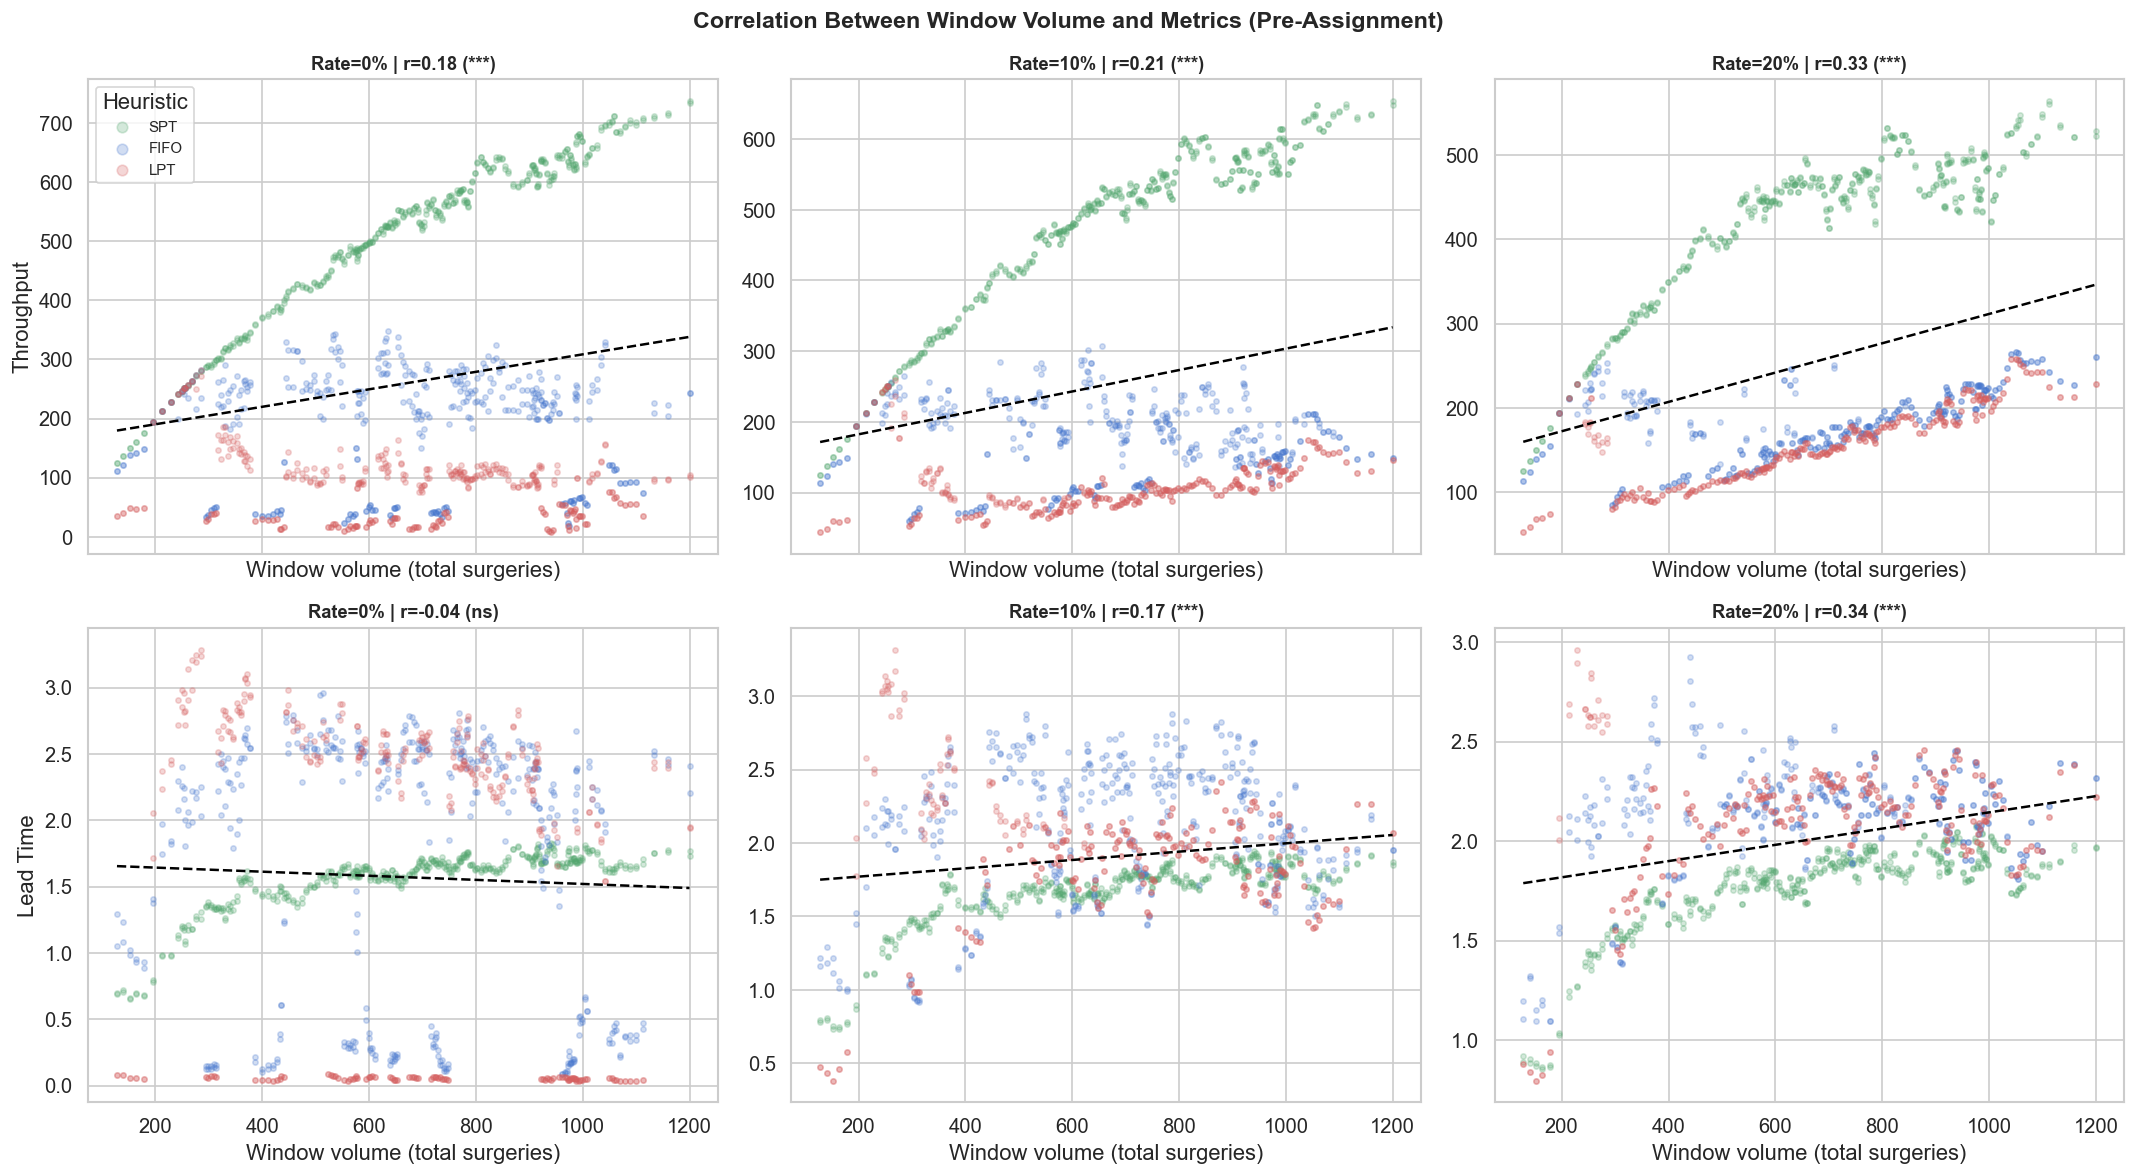

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True)

rates_show = [0.00, 0.10, 0.20]

for row_i, metric in enumerate(['throughput', 'lead_time']):
    for col_i, rate in enumerate(rates_show):
        ax = axes[row_i, col_i]
        sub = df[df['random_rate'] == rate]
        for heu in HEU_ORDER:
            grp = sub[sub['heuristica'] == heu]
            ax.scatter(grp['vol_ventana'], grp[metric],
                       color=HEU_PAL[heu], alpha=0.25, s=10, label=heu)
        x = sub['vol_ventana'].values
        y = sub[metric].values
        slope, intercept, r, p, _ = stats.linregress(x, y)
        x_line = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_line, slope * x_line + intercept,
                color='black', linewidth=1.5, linestyle='--', zorder=5)
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        ax.set_title(f'Rate={RATE_LABEL[rate]} | r={r:.2f} ({sig})', fontsize=11, fontweight='bold')
        ax.set_xlabel('Window volume (total surgeries)')
        if col_i == 0:
            ax.set_ylabel(metric.replace('_', ' ').title())
        if row_i == 0 and col_i == 0:
            ax.legend(title='Heuristic', markerscale=2, fontsize=9)

fig.suptitle('Correlation Between Window Volume and Metrics (Pre-Assignment)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_correlacion_volumen.png', bbox_inches='tight')
plt.show()

In [18]:
print(f"{'='*75}")
print(f"  CORRELACIONES DE PEARSON: vol_ventana vs metricas")
print(f"{'='*75}")
print(f"  {'Combinacion':<22}  {'Rate':>5}  {'r_TP':>7}  {'r_LT':>7}  {'r_uElec':>8}  {'r_uGlob':>8}")
print(f"  {'-'*62}")
for (combo, rate), grp in df.groupby(['tipo_asignacion', 'random_rate']):
    if rate not in [0.00, 0.10, 0.20]:
        continue
    r_tp, _ = stats.pearsonr(grp['vol_ventana'], grp['throughput'])
    r_lt, _ = stats.pearsonr(grp['vol_ventana'], grp['lead_time'])
    r_ue, _ = stats.pearsonr(grp['vol_ventana'], grp['util_elec_pct'])
    r_ug, _ = stats.pearsonr(grp['vol_ventana'], grp['util_global_pct'])
    print(f"  {combo:<22}  {RATE_LABEL[rate]:>5}  {r_tp:>7.3f}  {r_lt:>7.3f}  {r_ue:>8.3f}  {r_ug:>8.3f}")

  CORRELACIONES DE PEARSON: vol_ventana vs metricas
  Combinacion              Rate     r_TP     r_LT   r_uElec   r_uGlob
  --------------------------------------------------------------
  FIFO + Alternado           0%   -0.029   -0.065    -0.023     0.003
  FIFO + Alternado          10%   -0.024    0.166    -0.116    -0.070
  FIFO + Alternado          20%    0.544    0.284     0.099     0.156
  FIFO + Secuencial          0%   -0.039   -0.052    -0.028    -0.006
  FIFO + Secuencial         10%   -0.044    0.173    -0.140    -0.099
  FIFO + Secuencial         20%    0.508    0.248     0.052     0.112
  LPT + Alternado            0%   -0.320   -0.183    -0.102    -0.085
  LPT + Alternado           10%    0.153   -0.063    -0.274    -0.227
  LPT + Alternado           20%    0.814    0.253     0.243     0.295
  LPT + Secuencial           0%   -0.312   -0.193    -0.102    -0.084
  LPT + Secuencial          10%    0.177   -0.056    -0.265    -0.217
  LPT + Secuencial          20%    0.822   

> **Interpretación.** SPT mantiene una correlación alta entre volumen y throughput incluso con pre-asignación, aunque ligeramente inferior al r=0.97 del modelo base. Esto indica que la pre-asignación introduce ruido pero no destruye la relación fundamental de escalabilidad de SPT. FIFO sigue mostrando correlación baja, confirmando su techo de capacidad independiente del volumen.

## 11. ¿Qué combinación gana más iteraciones?
### 11.1 Mayor throughput por iteración

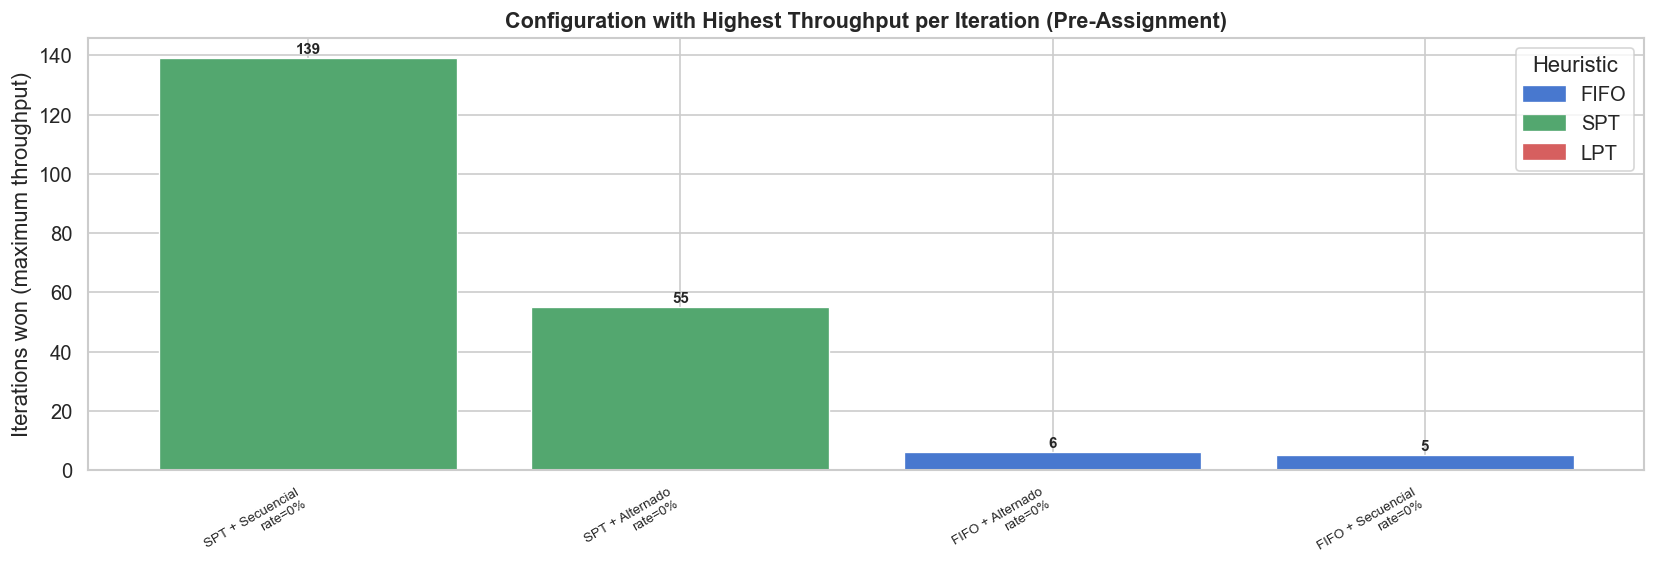

In [19]:
winner_tp = (
    df.sort_values(['iteracion','throughput'], ascending=[True, False])
    .groupby('iteracion').first().reset_index()
)
wins_tp = (
    winner_tp.groupby(['tipo_asignacion','random_rate'])
    .size().reset_index(name='wins').sort_values('wins', ascending=False)
)

fig, ax = plt.subplots(figsize=(14, 5))
bar_colors = [HEU_PAL[r.split(' + ')[0]] for r in wins_tp['tipo_asignacion']]
bars = ax.bar(range(len(wins_tp)), wins_tp['wins'],
              color=bar_colors, edgecolor='white', linewidth=0.8)
ax.set_xticks(range(len(wins_tp)))
ax.set_xticklabels(
    [f"{row['tipo_asignacion']}\nrate={RATE_LABEL[row['random_rate']]}" for _, row in wins_tp.iterrows()],
    rotation=30, ha='right', fontsize=8
)
ax.set_ylabel('Iterations won (maximum throughput)')
ax.set_title('Configuration with Highest Throughput per Iteration (Pre-Assignment)',
             fontsize=13, fontweight='bold')
for bar, val in zip(bars, wins_tp['wins']):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(int(val)), ha='center', va='bottom', fontsize=9, fontweight='bold')
legend_h = [mpatches.Patch(color=c, label=h) for h, c in HEU_PAL.items()]
ax.legend(handles=legend_h, title='Heuristic')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_wins_throughput.png', bbox_inches='tight')
plt.show()

> **Interpretación.** SPT con tasa 0% (sin pre-asignación) gana la mayoría de iteraciones, seguido por SPT con tasas bajas de pre-asignación. Esto refuerza que la pre-asignación aleatoria reduce el rendimiento máximo: la configuración óptima es siempre SPT con la menor interferencia aleatoria posible.

### 11.2 Menor lead time por iteración

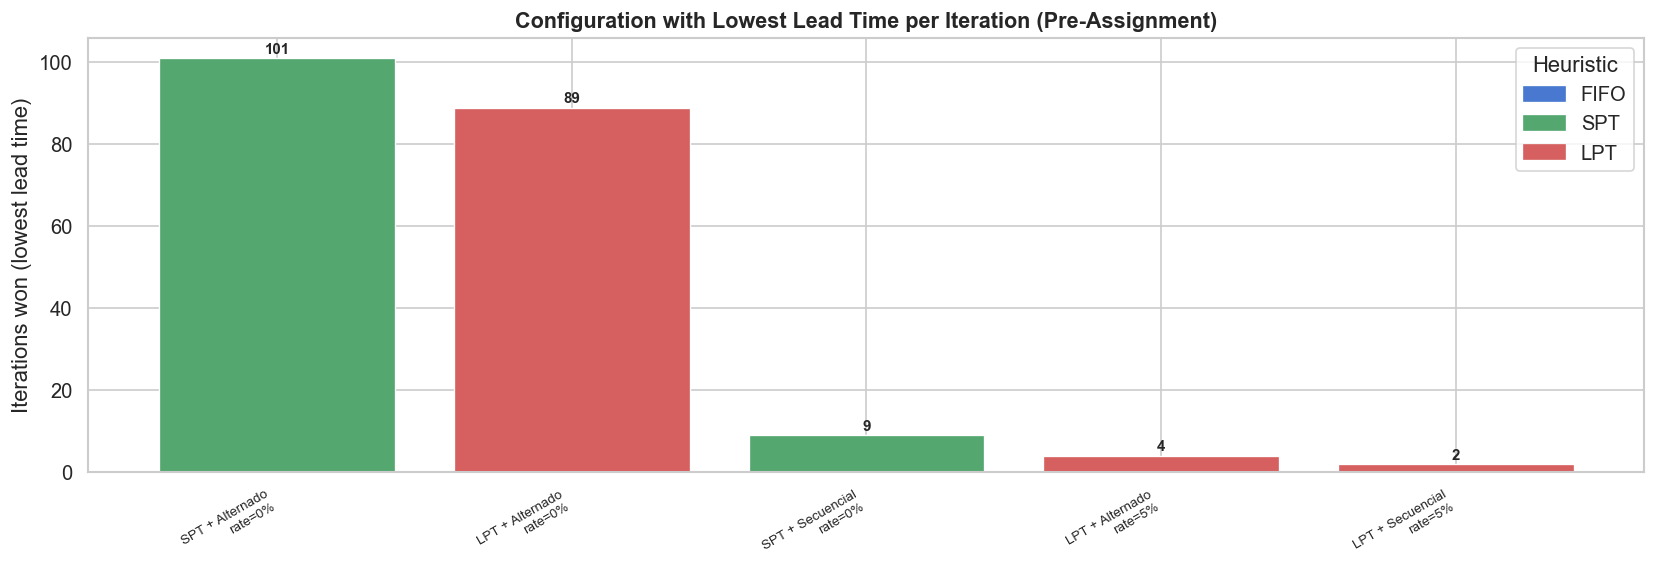

In [20]:
winner_lt = (
    df.sort_values(['iteracion','lead_time'], ascending=[True, True])
    .groupby('iteracion').first().reset_index()
)
wins_lt = (
    winner_lt.groupby(['tipo_asignacion','random_rate'])
    .size().reset_index(name='wins').sort_values('wins', ascending=False)
)

fig, ax = plt.subplots(figsize=(14, 5))
bar_colors = [HEU_PAL[r.split(' + ')[0]] for r in wins_lt['tipo_asignacion']]
bars = ax.bar(range(len(wins_lt)), wins_lt['wins'],
              color=bar_colors, edgecolor='white', linewidth=0.8)
ax.set_xticks(range(len(wins_lt)))
ax.set_xticklabels(
    [f"{row['tipo_asignacion']}\nrate={RATE_LABEL[row['random_rate']]}" for _, row in wins_lt.iterrows()],
    rotation=30, ha='right', fontsize=8
)
ax.set_ylabel('Iterations won (lowest lead time)')
ax.set_title('Configuration with Lowest Lead Time per Iteration (Pre-Assignment)',
             fontsize=13, fontweight='bold')
for bar, val in zip(bars, wins_lt['wins']):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(int(val)), ha='center', va='bottom', fontsize=9, fontweight='bold')
legend_h = [mpatches.Patch(color=c, label=h) for h, c in HEU_PAL.items()]
ax.legend(handles=legend_h, title='Heuristic')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_wins_leadtime.png', bbox_inches='tight')
plt.show()

> **Interpretación.** La misma advertencia sobre LPT aplica aquí: su bajo lead time es un artefacto de atender pocas cirugías. La comparación de lead time solo tiene validez cuando el throughput es comparable.

## 12. Evolución por iteración — Estabilidad temporal

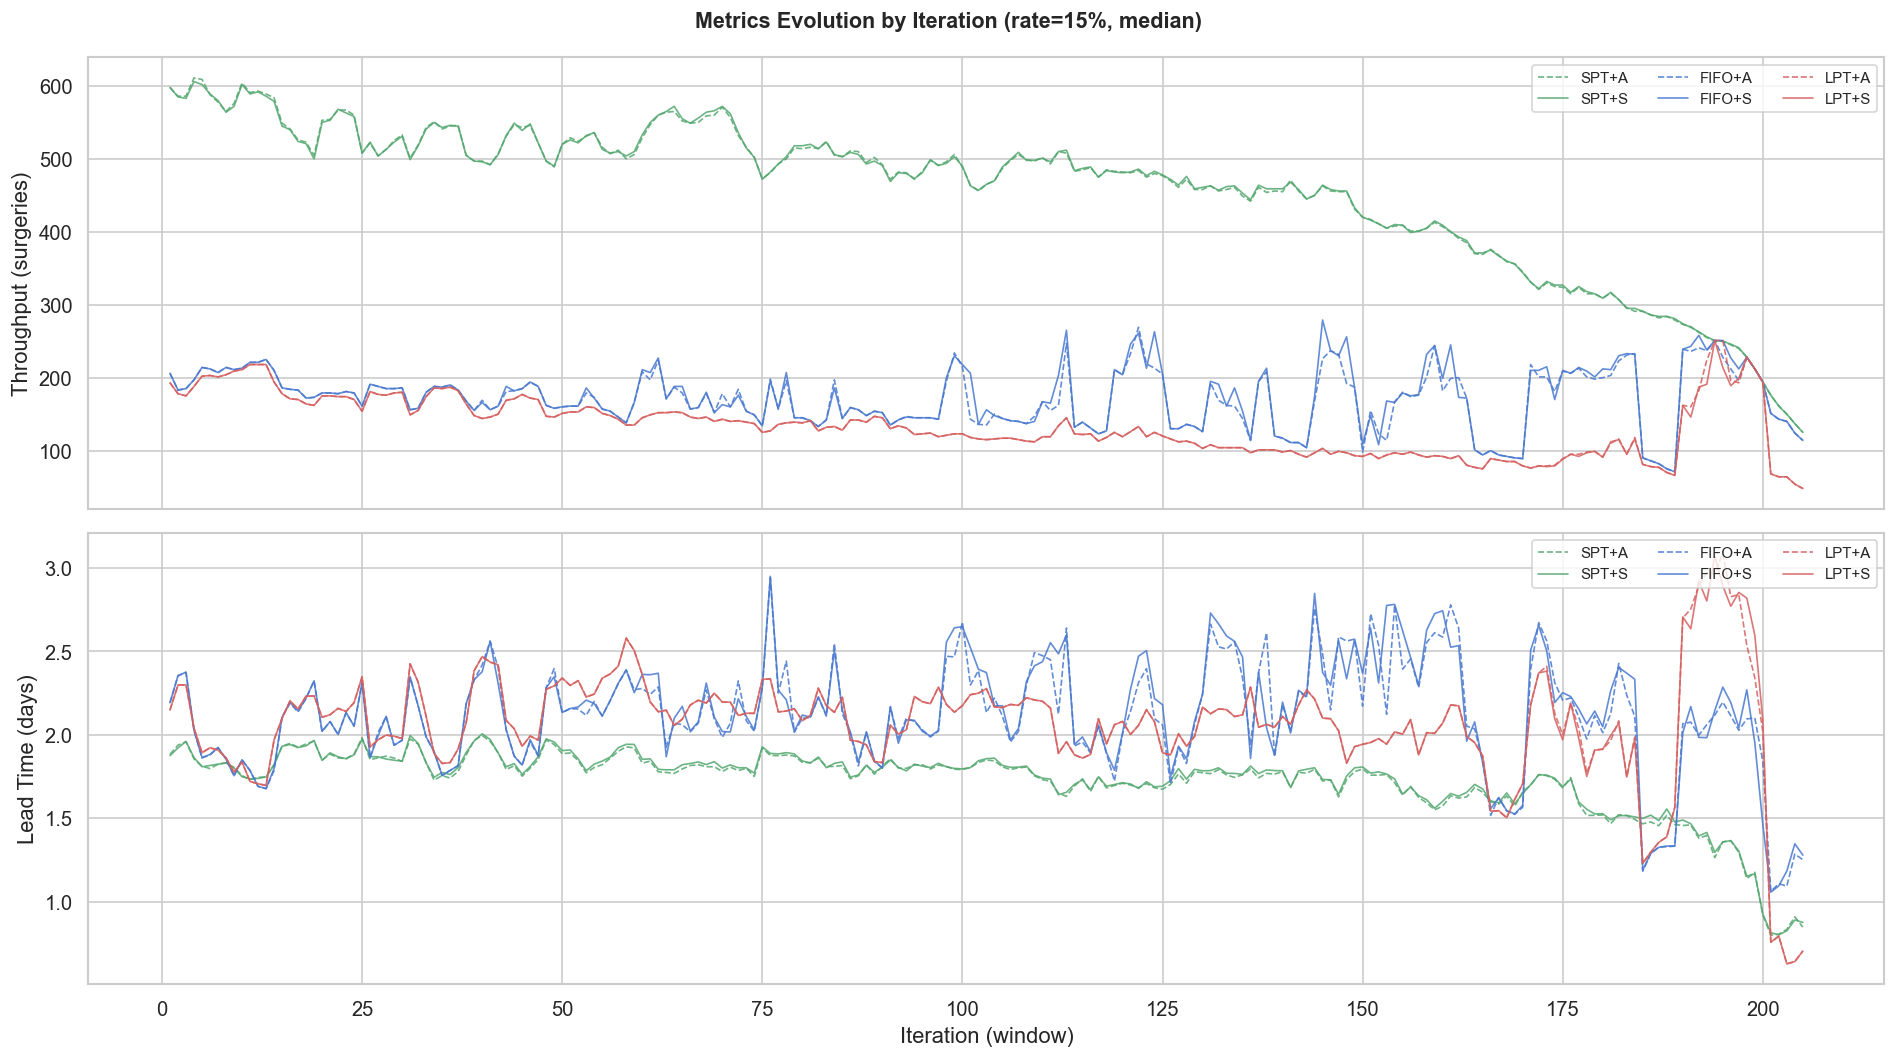

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

for ax, metric, ylabel in zip(
    axes,
    ['throughput', 'lead_time'],
    ['Throughput (surgeries)', 'Lead Time (days)']
):
    for heu in HEU_ORDER:
        for strat, ls in [('A', '--'), ('S', '-')]:
            sub = df[(df['heuristica'] == heu) &
                     (df['estrategia'] == strat) &
                     (df['random_rate'] == 0.15)]
            med_iter = sub.groupby('iteracion')[metric].median()
            ax.plot(med_iter.index, med_iter.values,
                    color=HEU_PAL[heu], linestyle=ls,
                    linewidth=1, alpha=0.85, label=f'{heu}+{strat}')
    ax.set_ylabel(ylabel)
    ax.legend(ncol=3, fontsize=9, loc='upper right')

axes[1].set_xlabel('Iteration (window)')
fig.suptitle('Metrics Evolution by Iteration (rate=15%, median)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_preassign_evolucion_iteraciones.png', bbox_inches='tight')
plt.show()

> **Interpretación.** La evolución temporal con tasa de pre-asignación del 15% confirma la estabilidad de los resultados: las curvas de cada heurística se mantienen bien separadas y sin cruces a lo largo de las iteraciones. La variabilidad inter-iteraciones refleja el efecto del volumen de la ventana.

## 13. Tabla resumen ejecutiva

In [22]:
summary_paper = (
    df.groupby(['tipo_asignacion', 'random_rate'])
    .agg(
        TP_mean    = ('throughput',          'mean'),
        TP_std     = ('throughput',          'std'),
        TP_median  = ('throughput',          'median'),
        LT_mean    = ('lead_time',           'mean'),
        LT_std     = ('lead_time',           'std'),
        uElec_mean = ('util_elec_pct',       'mean'),
        uElec_std  = ('util_elec_pct',       'std'),
        uGlob_mean = ('util_global_pct',     'mean'),
        uGlob_std  = ('util_global_pct',     'std'),
        Pre_mean   = ('pre_assigned_count',  'mean'),
        PrePct     = ('pre_assigned_pct',    'mean'),
    )
    .round(2)
    .sort_values('TP_mean', ascending=False)
)

summary_paper.to_csv('tabla_resumen_preasignacion.csv')
print('Tabla exportada a tabla_resumen_preasignacion.csv')
display(summary_paper)

Tabla exportada a tabla_resumen_preasignacion.csv


,,TP_mean,TP_std,TP_median,LT_mean,LT_std,uElec_mean,uElec_std,uGlob_mean,uGlob_std,Pre_mean,PrePct
tipo_asignacion,random_rate,,,,,,,,,,,
SPT + Secuencial,0.00,514.31,138.39,550.0,1.58,0.22,92.48,8.51,60.82,5.20,0.00,0.00
SPT + Alternado,0.00,512.71,138.26,547.0,1.56,0.21,91.61,8.59,60.30,5.26,0.00,0.00
SPT + Secuencial,0.05,500.41,130.53,536.0,1.65,0.23,89.50,7.80,59.03,4.80,32.13,6.53
SPT + Alternado,0.05,499.24,130.81,533.0,1.63,0.23,88.80,7.93,58.62,4.92,32.13,6.54
SPT + Secuencial,0.10,481.18,117.66,518.0,1.68,0.21,86.89,7.15,57.47,4.46,64.75,13.72
SPT + Alternado,0.10,480.41,117.61,517.0,1.67,0.21,86.51,7.21,57.24,4.50,64.75,13.74
SPT + Secuencial,0.15,457.03,103.41,489.0,1.73,0.21,85.24,6.88,56.48,4.31,97.27,21.77
SPT + Alternado,0.15,456.65,103.71,487.0,1.72,0.21,84.98,6.94,56.32,4.39,97.27,21.78
SPT + Secuencial,0.20,427.24,86.80,454.0,1.78,0.22,84.74,7.16,56.18,4.62,129.82,31.32


In [23]:
print(f"\n{'Combinacion':<22} {'Rate':>5} | {'TP mean+/-std':>16} | {'LT mean+/-std':>14} | {'uElec%':>8} | {'Pre#':>5} | {'Pre%':>6}")
print('-' * 90)
for (combo, rate), row in summary_paper.iterrows():
    print(
        f"{combo:<22} {RATE_LABEL[rate]:>5} | "
        f"{row['TP_mean']:>6.0f} +/- {row['TP_std']:>5.0f} | "
        f"{row['LT_mean']:>5.2f} +/- {row['LT_std']:>4.2f} | "
        f"{row['uElec_mean']:>7.1f}% | "
        f"{row['Pre_mean']:>5.0f} | "
        f"{row['PrePct']:>5.1f}%"
    )


Combinacion             Rate |    TP mean+/-std |  LT mean+/-std |   uElec% |  Pre# |   Pre%
------------------------------------------------------------------------------------------
SPT + Secuencial          0% |    514 +/-   138 |  1.58 +/- 0.22 |    92.5% |     0 |   0.0%
SPT + Alternado           0% |    513 +/-   138 |  1.56 +/- 0.21 |    91.6% |     0 |   0.0%
SPT + Secuencial          5% |    500 +/-   131 |  1.65 +/- 0.23 |    89.5% |    32 |   6.5%
SPT + Alternado           5% |    499 +/-   131 |  1.63 +/- 0.23 |    88.8% |    32 |   6.5%
SPT + Secuencial         10% |    481 +/-   118 |  1.68 +/- 0.21 |    86.9% |    65 |  13.7%
SPT + Alternado          10% |    480 +/-   118 |  1.67 +/- 0.21 |    86.5% |    65 |  13.7%
SPT + Secuencial         15% |    457 +/-   103 |  1.73 +/- 0.21 |    85.2% |    97 |  21.8%
SPT + Alternado          15% |    457 +/-   104 |  1.72 +/- 0.21 |    85.0% |    97 |  21.8%
SPT + Secuencial         20% |    427 +/-    87 |  1.78 +/- 0.22 |    8

---
## 14. Conclusiones

### 14.1 Impacto de la pre-asignación aleatoria

El análisis de 205 iteraciones con 30 combinaciones por iteración revela que la pre-asignación aleatoria tiene un **costo neto sobre el throughput** que es proporcional a la tasa de inserción. Este costo proviene de la fragmentación del Gantt: las cirugías colocadas al azar generan huecos que la heurística no puede rellenar eficientemente.

### 14.2 Ranking de configuraciones

1. **SPT + Secuencial + 0% pre-asignación**: Máximo throughput y utilización. Equivalente al modelo base sin perturbación.
2. **SPT + Secuencial + 5% pre-asignación**: Pérdida marginal de throughput (~1-3%) con el beneficio operacional de tener algunas cirugías pre-programadas.
3. **SPT + Alternado + 0-5% pre-asignación**: Alternativa robusta cuando la flexibilidad intradía es prioritaria.

### 14.3 Recomendación

La pre-asignación aleatoria puede justificarse operacionalmente (por ejemplo, para acomodar preferencias de equipo quirúrgico o disponibilidad de especialistas), pero debe mantenerse en **tasas bajas (≤5%)** para minimizar el impacto sobre la eficiencia del sistema. Tasas superiores al 15% producen pérdidas significativas de throughput sin beneficios compensatorios evidentes en el modelo.

### 14.4 Limitaciones

- La pre-asignación es **puramente aleatoria**; en la práctica, las pre-asignaciones responden a criterios clínicos (disponibilidad de especialista, tipo de cirugía) que podrían resultar en una fragmentación menor.
- El seed fijo (42) garantiza reproducibilidad pero los resultados podrían variar con otros seeds.
- Las mismas limitaciones del modelo base aplican: ventanas solapadas, sin tiempos de setup, sin especialidades.